<a href="https://colab.research.google.com/github/672023033-hub/Image-Enhancement-Using-Brightness-Adjustment-and-CLAHE/blob/main/BRIGHTNESS_%26_CLAHE_672023033.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Penyesuaian Kecerahan dan CLAHE

Untuk memulai, kita akan membutuhkan pustaka `opencv-python` untuk pemrosesan gambar dan `matplotlib` untuk menampilkan hasilnya. Jika Anda belum menginstalnya, pastikan untuk melakukannya.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Instal opencv-python jika belum terinstal
# !pip install opencv-python

Pertama, mari kita muat gambar contoh. Anda bisa mengganti path gambar di bawah ini dengan gambar Anda sendiri.

Saving gambar 1.jpg to gambar 1 (2).jpg
Mengunggah: gambar 1 (2).jpg


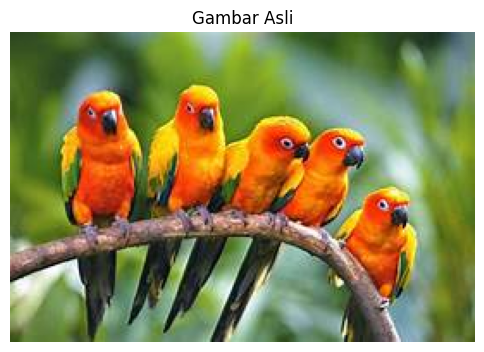

In [ ]:
from google.colab import files
import os

# Pilihan input gambar:
# 1. Upload gambar dari komputer Anda
# 2. Masukkan path gambar jika sudah ada di Colab atau Drive Anda

image_source_option = 'upload' # Ganti dengan 'path' jika Anda ingin memasukkan path secara manual

original_image = None

if image_source_option == 'upload':
    uploaded = files.upload()
    if uploaded:
        image_filename = list(uploaded.keys())[0]
        print(f"Mengunggah: {image_filename}")
        image_path = image_filename
        original_image = cv2.imread(image_path)
        if original_image is None:
            print(f"Gagal memuat gambar dari file yang diunggah: {image_filename}")
    else:
        print("Tidak ada file yang diunggah. Akan mencoba memuat dari path default atau membuat dummy.")

if original_image is None:
    # Jika tidak diunggah atau pilihan path, coba path default atau buat dummy
    image_path = '/content/sample_data/bird.jpg' # Contoh path, ganti jika perlu
    try:
        if os.path.exists(image_path):
            original_image = cv2.imread(image_path)
            if original_image is None:
                raise FileNotFoundError # Jika cv2.imread gagal padahal file ada
        else:
            raise FileNotFoundError
    except FileNotFoundError:
        print(f"File tidak ditemukan di {image_path}. Membuat gambar dummy.")
        # Membuat gambar dummy (warna abu-abu dengan beberapa kotak)
        original_image = np.zeros((300, 300, 3), dtype=np.uint8)
        original_image.fill(128) # Warna abu-abu
        cv2.rectangle(original_image, (50, 50), (150, 150), (255, 0, 0), -1) # Kotak biru
        cv2.rectangle(original_image, (100, 100), (200, 200), (0, 255, 0), -1) # Kotak hijau
        cv2.circle(original_image, (250, 250), 40, (0, 0, 255), -1) # Lingkaran merah


original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB) # Konversi BGR ke RGB untuk matplotlib

plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.title('Gambar Asli')
plt.axis('off')
plt.show()

### 1. Penyesuaian Kecerahan (Brightness Adjustment)

Penyesuaian kecerahan dilakukan dengan menambahkan atau mengurangi nilai piksel. Anda bisa mengontrol seberapa banyak kecerahan yang ingin ditambahkan dengan parameter `brightness_factor`. Nilai positif akan mencerahkan gambar, sedangkan nilai negatif akan menggelapkannya.

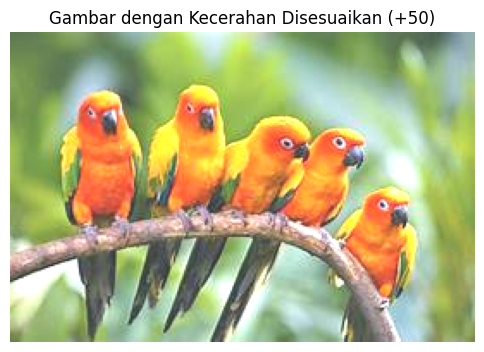

In [ ]:
brightness_factor = 50 # Tambahkan 50 ke setiap piksel (untuk mencerahkan)

bright_image = cv2.add(original_image, brightness_factor) # Mencerahkan gambar

plt.figure(figsize=(6, 6))
plt.imshow(bright_image)
plt.title(f'Gambar dengan Kecerahan Disesuaikan (+{brightness_factor})')
plt.axis('off')
plt.show()

### 2. CLAHE (Contrast Limited Adaptive Histogram Equalization)

CLAHE adalah teknik untuk meningkatkan kontras gambar, terutama di area yang berbeda-beda. Ini sangat berguna untuk gambar dengan rentang dinamis yang sempit atau pencahayaan yang tidak merata. Kita perlu mengonversi gambar ke ruang warna Lab, menerapkan CLAHE pada saluran L (Lightness), dan kemudian mengonversinya kembali ke RGB.

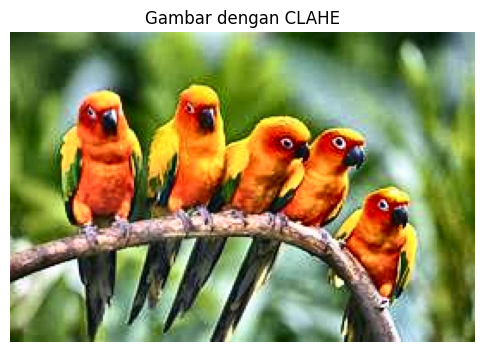

In [ ]:
clahe_image = cv2.cvtColor(original_image, cv2.COLOR_RGB2LAB)

# Buat objek CLAHE
# clipLimit adalah ambang batas untuk membatasi peningkatan kontras
# tileGridSize mendefinisikan ukuran daerah yang diterapkan CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# Terapkan CLAHE ke saluran L (Lightness)
clahe_image[:,:,0] = clahe.apply(clahe_image[:,:,0])

# Konversi kembali ke RGB
clahe_image = cv2.cvtColor(clahe_image, cv2.COLOR_LAB2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(clahe_image)
plt.title('Gambar dengan CLAHE')
plt.axis('off')
plt.show()

### Perbandingan Hasil

Berikut adalah perbandingan ketiga gambar:

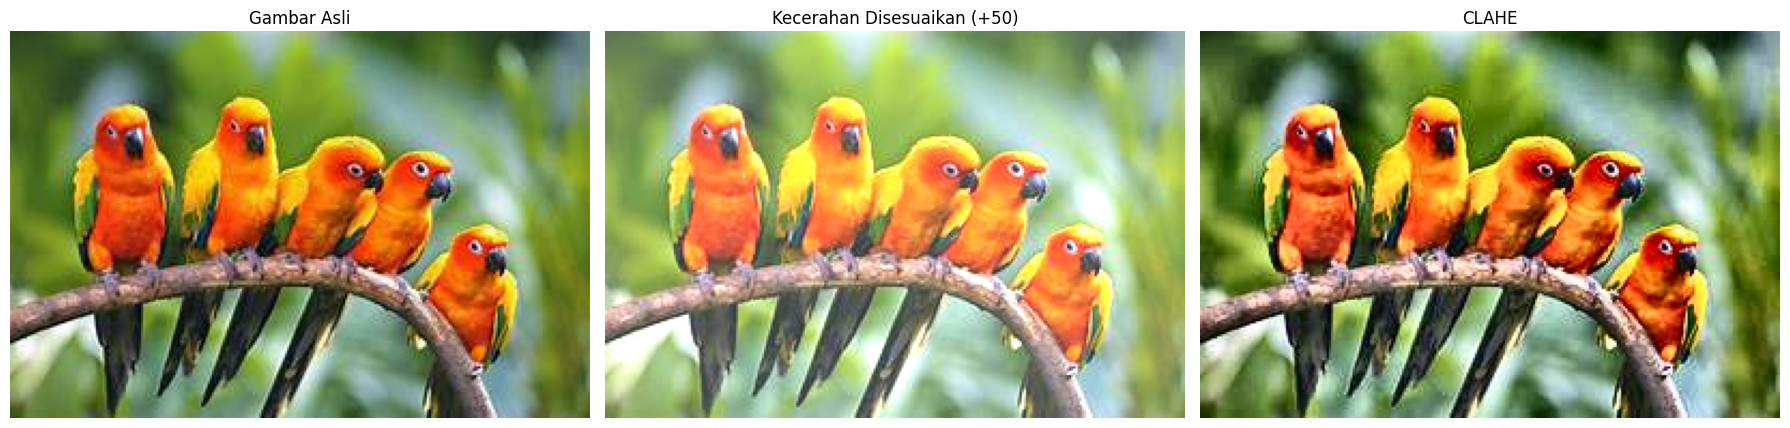

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(original_image)
axes[0].set_title('Gambar Asli')
axes[0].axis('off')

axes[1].imshow(bright_image)
axes[1].set_title(f'Kecerahan Disesuaikan (+{brightness_factor})')
axes[1].axis('off')

axes[2].imshow(clahe_image)
axes[2].set_title('CLAHE')
axes[2].axis('off')

plt.tight_layout()
plt.show()